<a href="https://colab.research.google.com/github/minyi-k03/Linear-Algebra/blob/main/%5B%EC%84%A0%ED%98%95%EB%8C%80%EC%88%98%ED%95%99%5D%EC%B1%8C%EB%A6%B0%EC%A7%80.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%%writefile my_utils.py
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

INF = 1000
LEN = 100

def to_homo(p):
    return np.array([p[0], p[1], 1.0], dtype=float)

def to_cart(hp):
    return np.array([hp[0], hp[1]], dtype=float)

def translate(p, dx, dy):
    hp = to_homo(p)
    m = np.array([
        [1.0, 0.0, dx],
        [0.0, 1.0, dy],
        [0.0, 0.0, 1.0]
    ])
    return to_cart(np.dot(m, hp))

def rotate(p, theta):
    hp = to_homo(p)
    c, s = np.cos(theta), np.sin(theta)
    m = np.array([
        [c, -s, 0.0],
        [s,  c, 0.0],
        [0.0, 0.0, 1.0]
    ])
    return to_cart(np.dot(m, hp))

def scale(p, sx, sy):
    hp = to_homo(p)
    m = np.array([
        [sx,  0.0, 0.0],
        [0.0, sy,  0.0],
        [0.0, 0.0, 1.0]
    ])
    return to_cart(np.dot(m, hp))

def shear_x(p, sx):
    hp = to_homo(p)
    m = np.array([
        [1.0, sx,  0.0],
        [0.0, 1.0, 0.0],
        [0.0, 0.0, 1.0]
    ])
    return to_cart(np.dot(m, hp))

def shear_y(p, sy):
    hp = to_homo(p)
    m = np.array([
        [1.0, 0.0, 0.0],
        [sy,  1.0, 0.0],
        [0.0, 0.0, 1.0]
    ])
    return to_cart(np.dot(m, hp))

def reflect_x(p):
    hp = to_homo(p)
    m = np.array([
        [1.0,  0.0, 0.0],
        [0.0, -1.0, 0.0],
        [0.0,  0.0, 1.0]
    ])
    return to_cart(np.dot(m, hp))

def reflect_y(p):
    hp = to_homo(p)
    m = np.array([
        [-1.0, 0.0, 0.0],
        [ 0.0, 1.0, 0.0],
        [ 0.0, 0.0, 1.0]
    ])
    return to_cart(np.dot(m, hp))

def reflect_origin(p):
    hp = to_homo(p)
    m = np.array([
        [-1.0,  0.0, 0.0],
        [ 0.0, -1.0, 0.0],
        [ 0.0,  0.0, 1.0]
    ])
    return to_cart(np.dot(m, hp))

def reflect_yx(p):
    hp = to_homo(p)
    m = np.array([
        [0.0, 1.0, 0.0],
        [1.0, 0.0, 0.0],
        [0.0, 0.0, 1.0]
    ])
    return to_cart(np.dot(m, hp))

def draw_axis(ax):
    ax.axhline(0, color='#64748B', alpha=0.35, linewidth=1)
    ax.axvline(0, color='#64748B', alpha=0.35, linewidth=1)
    ax.set_xlim(-INF, INF)
    ax.set_ylim(-INF, INF)
    ax.set_aspect('equal')
    ax.set_facecolor('#0B0F19')  # 사막 행성의 밤하늘 톤

def draw_rectangle(ax, p1, p2, p3, p4, color='#94A3B8', alpha=1.0):
    poly = Polygon([p1, p2, p3, p4], facecolor=color, edgecolor='#0F172A', linewidth=0.6, alpha=alpha)
    ax.add_patch(poly)


def draw_spice_atmosphere(ax, base_points):
    positions = [
        (-800, 700), (-650, 400), (-450, 850), (-250, 600),
        (300, 750), (600, 500), (820, 800), (750, 250),
        (-850, -400), (-600, -750), (-350, -600), (200, -800),
        (550, -650), (800, -350), (-150, -300), (150, 450)
    ]
    for x, y in positions:
        pts = [translate(p, -LEN/2, -LEN/2) for p in base_points]
        pts = [scale(p, 0.15, 0.15) for p in pts]
        pts = [rotate(p, np.pi / 4.0) for p in pts]
        pts = [translate(p, x, y) for p in pts]
        draw_rectangle(ax, pts[0], pts[1], pts[2], pts[3], color='#F59E0B', alpha=0.65)

Writing my_utils.py


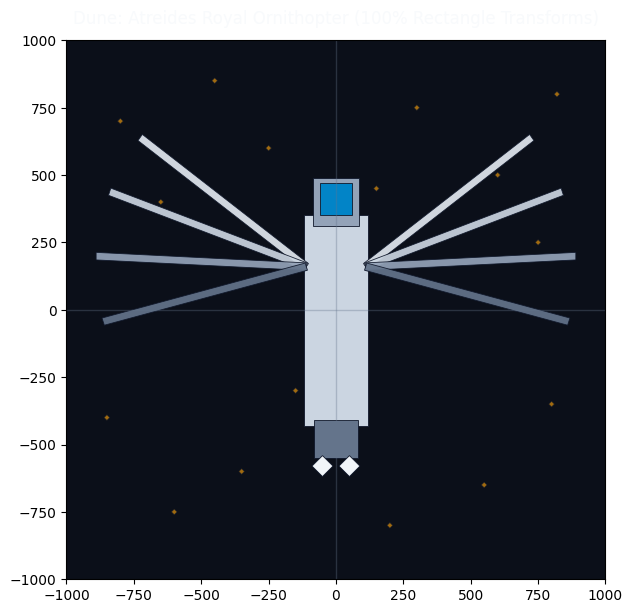

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from my_utils import (
    INF, LEN,
    draw_axis,
    draw_rectangle,
    translate,
    rotate,
    scale,
    shear_y,
    reflect_x,
    reflect_y,
    draw_spice_atmosphere
)

def draw_fuselage(ax, base_pts):
    # (1) 메인 중앙 동체 프레임
    b = [translate(p, -LEN/2, -LEN/2) for p in base_pts]
    b = [scale(p, 2.4, 7.8) for p in b]
    b = [translate(p, 0, -40) for p in b]
    draw_rectangle(ax, b[0], b[1], b[2], b[3], color='#CBD5E1')

    # (2) 상단 조종석 캐빈 (Cockpit Base)
    c = [translate(p, -LEN/2, -LEN/2) for p in base_pts]
    c = [scale(p, 1.7, 1.8) for p in c]
    c = [translate(p, 0, 400) for p in c]
    draw_rectangle(ax, c[0], c[1], c[2], c[3], color='#94A3B8')

    # (3) 캐노피 윈도우 글래스 (미적 요소)
    w = [translate(p, -LEN/2, -LEN/2) for p in base_pts]
    w = [scale(p, 1.2, 1.2) for p in w]
    w = [translate(p, 0, 410) for p in w]
    draw_rectangle(ax, w[0], w[1], w[2], w[3], color='#0284C7')

    # (4) 테일 붐 및 하단 엔진 블록
    t = [translate(p, -LEN/2, -LEN/2) for p in base_pts]
    t = [scale(p, 1.6, 1.4) for p in t]
    t = [translate(p, 0, -480) for p in t]
    draw_rectangle(ax, t[0], t[1], t[2], t[3], color='#64748B')

    # (5) 트윈 테일 랜딩 패드 (우측 생성 후 y축 대칭으로 좌측 생성)
    p_right = [translate(p, -LEN/2, -LEN/2) for p in base_pts]
    p_right = [scale(p, 0.55, 0.55) for p in p_right]
    p_right = [rotate(p, np.pi / 4.0) for p in p_right]
    p_right = [translate(p, 50, -580) for p in p_right]
    p_left = [reflect_y(pt) for pt in p_right]

    draw_rectangle(ax, p_right[0], p_right[1], p_right[2], p_right[3], color='#F1F5F9')
    draw_rectangle(ax, p_left[0], p_left[1], p_left[2], p_left[3], color='#F1F5F9')

def draw_wings(ax, base_pts):
    # 영화/자료 기준 4단계 전개 각도 (상단에서 하단으로 방사형 전개)
    wing_angles = [np.radians(35), np.radians(18), np.radians(0), np.radians(-18)]
    wing_colors = ['#E2E8F0', '#CBD5E1', '#94A3B8', '#64748B']

    for i, angle in enumerate(wing_angles):
        # (1) 우측 날개: 기본 변환 -> 회전 -> 숄더 피벗에 부착
        rw = [translate(p, 0.0, -LEN/2) for p in base_pts]    # 밑변 중앙을 원점 피벗으로 정렬
        rw = [scale(p, 7.8, 0.28) for p in rw]                 # 얇고 긴 초장축 블레이드
        rw = [shear_y(p, 0.05) for p in rw]                    # 블레이드 휨 변환
        rw = [rotate(p, angle) for p in rw]                    # 각도 회전
        rw = [translate(p, 110, 160) for p in rw]              # 동체 우측 관절 위치로 이동

        # (2) 좌측 날개: 우측 날개 정점에 y축 반전(reflect_y) 일괄 적용
        lw = [reflect_y(pt) for pt in rw]

        # 렌더링
        draw_rectangle(ax, rw[0], rw[1], rw[2], rw[3], color=wing_colors[i], alpha=0.92)
        draw_rectangle(ax, lw[0], lw[1], lw[2], lw[3], color=wing_colors[i], alpha=0.92)

def draw_object(ax):
    p1 = np.array([0, 0])
    p2 = np.array([LEN, 0])
    p3 = np.array([LEN, LEN])
    p4 = np.array([0, LEN])

    # 배경 미적 요소 (스파이스 대기 입자)
    draw_spice_atmosphere(ax, [p1, p2, p3, p4])

    # 주 객체 드로잉
    draw_fuselage(ax, [p1, p2, p3, p4])
    draw_wings(ax, [p1, p2, p3, p4])


if __name__ == '__main__':
    fig, ax = plt.subplots(figsize=(7, 7))
    draw_axis(ax)
    draw_object(ax)
    plt.title("Dune: Atreides Royal Ornithopter (100% Rectangle Transforms)", color='#F8FAFC', pad=12)
    plt.show()